# ELEVVO NLP INTERNSHIP
# TASK 02: NEWS CATEGORY CLASSIFICATION

INSTALL REQUIRED LIBRARIES

In [1]:
!pip install -q datasets pandas numpy matplotlib seaborn scikit-learn nltk

IMPORT LIBRARIES

In [2]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

from datasets import load_dataset

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import nltk
from nltk.corpus import stopwords

print("Libraries imported successfully!")

Libraries imported successfully!


DOWNLOAD STOPWORDS

In [3]:
nltk.download("stopwords", quiet=True)

stop_words = set(stopwords.words("english"))

# Preserve negation words
stop_words = stop_words - {"not", "no", "nor"}

print("Stopwords downloaded successfully!")

Stopwords downloaded successfully!


LOAD AG NEWS DATASET

In [4]:

dataset = load_dataset("fancyzhx/ag_news")

train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Dataset loaded successfully!")

print("\nTraining Dataset:")
print(train_df.head())

print("\nTesting Dataset:")
print(test_df.head())

print("\nTraining Shape:", train_df.shape)
print("Testing Shape:", test_df.shape)

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

Dataset loaded successfully!

Training Dataset:
                                                text  label
0  Wall St. Bears Claw Back Into the Black (Reute...      2
1  Carlyle Looks Toward Commercial Aerospace (Reu...      2
2  Oil and Economy Cloud Stocks' Outlook (Reuters...      2
3  Iraq Halts Oil Exports from Main Southern Pipe...      2
4  Oil prices soar to all-time record, posing new...      2

Testing Dataset:
                                                text  label
0  Fears for T N pension after talks Unions repre...      2
1  The Race is On: Second Private Team Sets Launc...      3
2  Ky. Company Wins Grant to Study Peptides (AP) ...      3
3  Prediction Unit Helps Forecast Wildfires (AP) ...      3
4  Calif. Aims to Limit Farm-Related Smog (AP) AP...      3

Training Shape: (120000, 2)
Testing Shape: (7600, 2)


 EXPLORE DATASET

In [5]:
print("\nTraining Dataset Information:")
print(train_df.info())

print("\nMissing Values:")
print(train_df.isnull().sum())

print("\nCategory Distribution:")
print(train_df["label"].value_counts().sort_index())


Training Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   text    120000 non-null  object
 1   label   120000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 1.8+ MB
None

Missing Values:
text     0
label    0
dtype: int64

Category Distribution:
label
0    30000
1    30000
2    30000
3    30000
Name: count, dtype: int64


In [6]:
class_names = ["World", "Sports", "Business", "Sci/Tech"]

# Add readable category names
train_df["category"] = train_df["label"].map(
    {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}
)

test_df["category"] = test_df["label"].map(
    {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}
)

VISUALIZE CATEGORY DISTRIBUTION

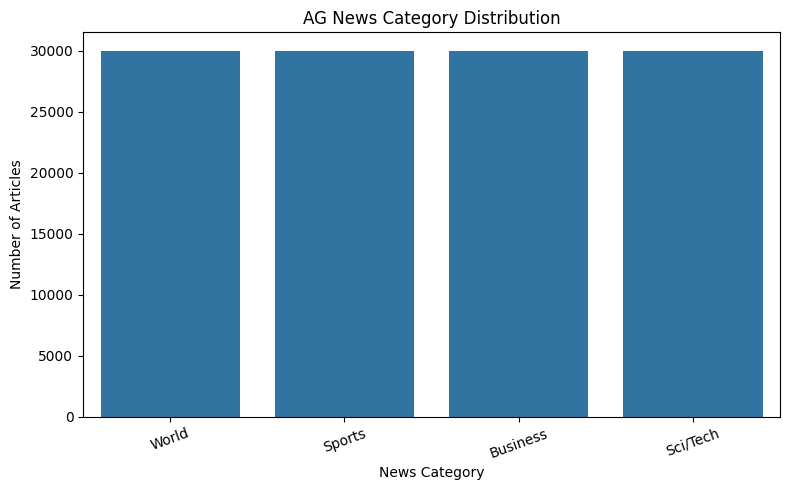

In [7]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x="category",
    order=class_names
)

plt.title("AG News Category Distribution")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

TEXT PREPROCESSING

In [8]:

def clean_text(text):

    text = text.lower()

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Keep alphabets and spaces
    text = re.sub(r"[^a-z\s]", " ", text)

    # Split text into words
    words = text.split()

    # Remove stopwords
    words = [
        word for word in words
        if word not in stop_words
    ]

    return " ".join(words)


train_df["cleaned_text"] = train_df["text"].apply(clean_text)
test_df["cleaned_text"] = test_df["text"].apply(clean_text)

print("Text preprocessing completed!")

print("\nOriginal News:")
print(train_df["text"].iloc[0])

print("\nCleaned News:")
print(train_df["cleaned_text"].iloc[0])

Text preprocessing completed!

Original News:
Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.

Cleaned News:
wall st bears claw back black reuters reuters short sellers wall street dwindling band ultra cynics seeing green


SEPARATE FEATURES AND LABELS

In [9]:
X_train = train_df["cleaned_text"]
y_train = train_df["label"]

X_test = test_df["cleaned_text"]
y_test = test_df["label"]

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))


Training Samples: 120000
Testing Samples: 7600


TF-IDF FEATURE EXTRACTION

In [10]:
tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("\nTF-IDF Feature Extraction Completed!")

print("Training Matrix Shape:", X_train_tfidf.shape)
print("Testing Matrix Shape:", X_test_tfidf.shape)


TF-IDF Feature Extraction Completed!
Training Matrix Shape: (120000, 20000)
Testing Matrix Shape: (7600, 20000)


TRAIN LOGISTIC REGRESSION MODEL

In [11]:
lr_model = LogisticRegression(
    max_iter=1000
)

lr_model.fit(X_train_tfidf, y_train)

print("\nLogistic Regression Model Trained Successfully!")


Logistic Regression Model Trained Successfully!


MAKE PREDICTIONS

In [12]:
lr_predictions = lr_model.predict(X_test_tfidf)

EVALUATE LOGISTIC REGRESSION

In [13]:
lr_accuracy = accuracy_score(
    y_test,
    lr_predictions
)

print("\nLogistic Regression Accuracy:")
print(f"{lr_accuracy * 100:.2f}%")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        lr_predictions,
        target_names=class_names
    )
)


Logistic Regression Accuracy:
91.97%

Classification Report:
              precision    recall  f1-score   support

       World       0.94      0.91      0.92      1900
      Sports       0.95      0.98      0.97      1900
    Business       0.89      0.89      0.89      1900
    Sci/Tech       0.90      0.90      0.90      1900

    accuracy                           0.92      7600
   macro avg       0.92      0.92      0.92      7600
weighted avg       0.92      0.92      0.92      7600



CONFUSION MATRIX

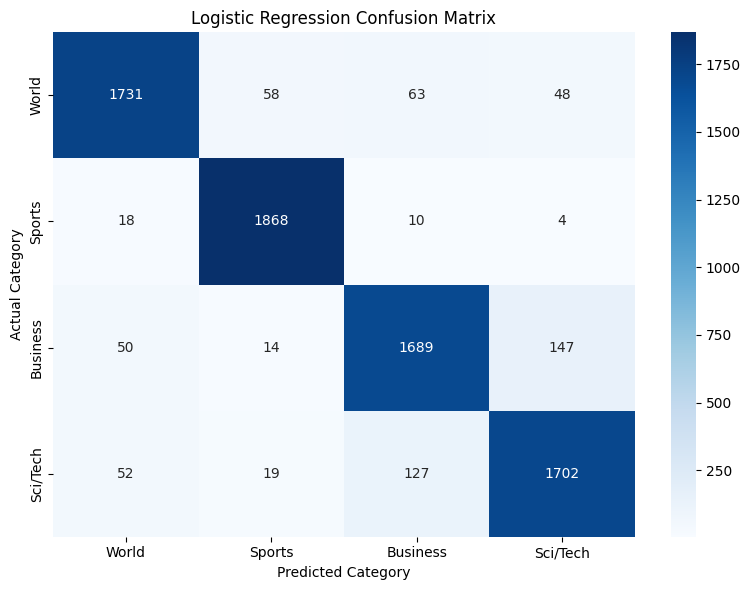

In [14]:
cm = confusion_matrix(
    y_test,
    lr_predictions
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()

FREQUENT WORDS IN EACH CATEGORY

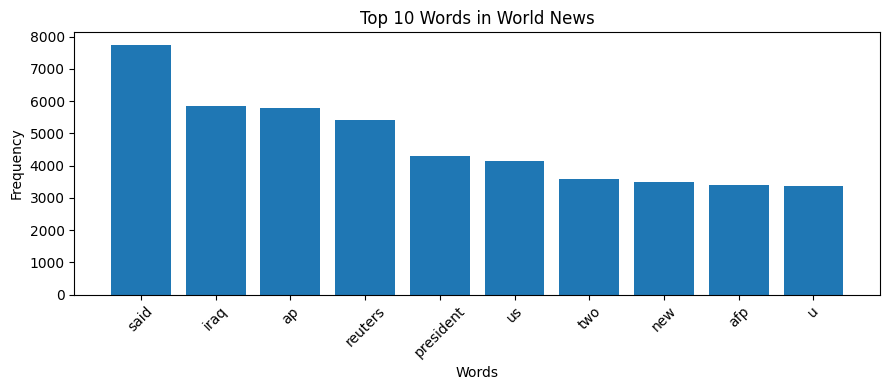

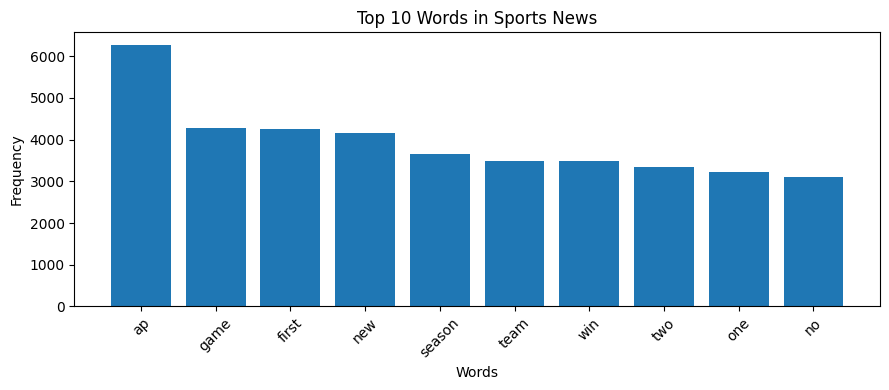

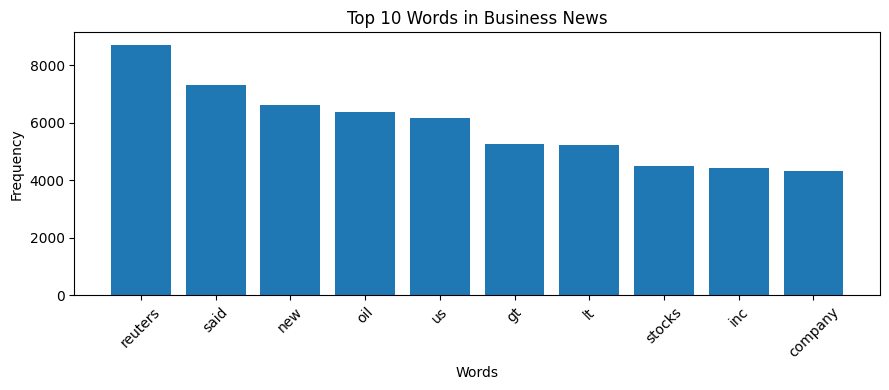

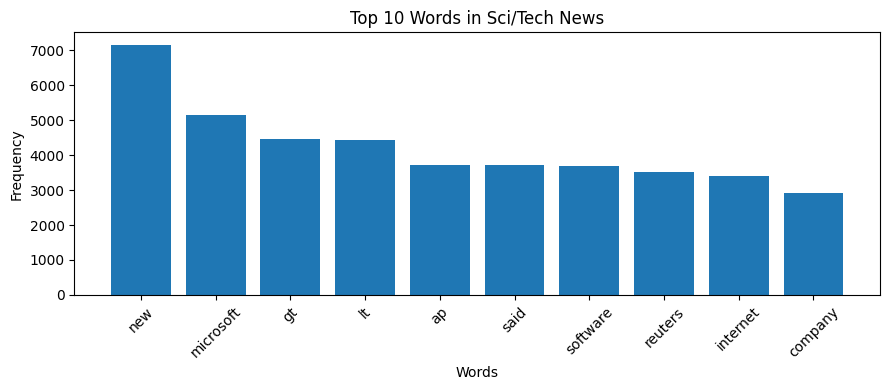

In [15]:
for label, category in enumerate(class_names):

    category_text = " ".join(
        train_df.loc[
            train_df["label"] == label,
            "cleaned_text"
        ]
    )

    word_counts = Counter(category_text.split())

    top_words = word_counts.most_common(10)

    words = [item[0] for item in top_words]
    counts = [item[1] for item in top_words]

    plt.figure(figsize=(9, 4))

    plt.bar(words, counts)

    plt.title(f"Top 10 Words in {category} News")
    plt.xlabel("Words")
    plt.ylabel("Frequency")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

TRAIN NAIVE BAYES MODEL

In [16]:
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_predictions = nb_model.predict(X_test_tfidf)

nb_accuracy = accuracy_score(
    y_test,
    nb_predictions
)

print("\nNaive Bayes Accuracy:")
print(f"{nb_accuracy * 100:.2f}%")


Naive Bayes Accuracy:
90.17%


COMPARE BOTH MODELS


Model Comparison:
                 Model  Accuracy (%)
0  Logistic Regression     91.973684
1          Naive Bayes     90.171053


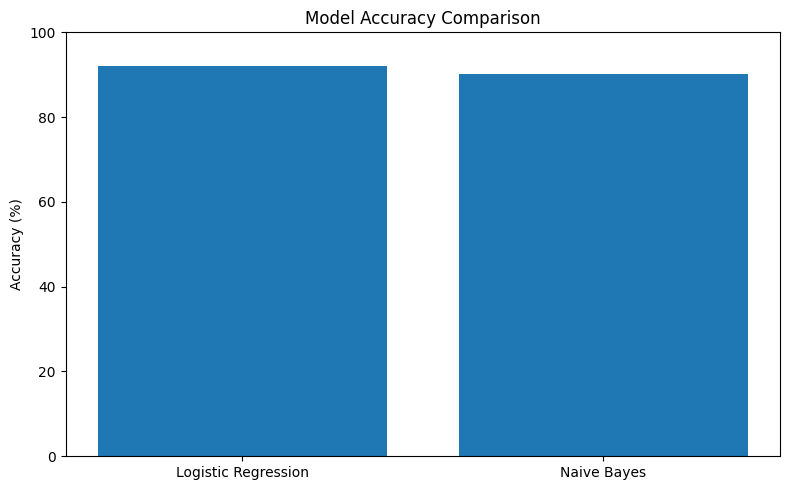

In [17]:
model_names = [
    "Logistic Regression",
    "Naive Bayes"
]

model_accuracies = [
    lr_accuracy * 100,
    nb_accuracy * 100
]

results_df = pd.DataFrame({
    "Model": model_names,
    "Accuracy (%)": model_accuracies
})

print("\nModel Comparison:")
print(results_df)

plt.figure(figsize=(8, 5))

plt.bar(
    model_names,
    model_accuracies
)

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

TEST CUSTOM NEWS ARTICLES

In [18]:
def predict_news_category(news):

    cleaned_news = clean_text(news)

    news_vector = tfidf.transform([cleaned_news])

    prediction = lr_model.predict(news_vector)[0]

    category = class_names[prediction]

    return category

sample_news = [
    "The government announced a new international trade agreement today.",
    "The football team won the championship after an exciting final match.",
    "The company reported increased profits in the financial market.",
    "Scientists developed a new artificial intelligence technology."
]

print("\nCUSTOM NEWS PREDICTIONS:")

for news in sample_news:

    predicted_category = predict_news_category(news)

    print("\nNews:", news)
    print("Predicted Category:", predicted_category)


CUSTOM NEWS PREDICTIONS:

News: The government announced a new international trade agreement today.
Predicted Category: Business

News: The football team won the championship after an exciting final match.
Predicted Category: Sports

News: The company reported increased profits in the financial market.
Predicted Category: Business

News: Scientists developed a new artificial intelligence technology.
Predicted Category: Sci/Tech
